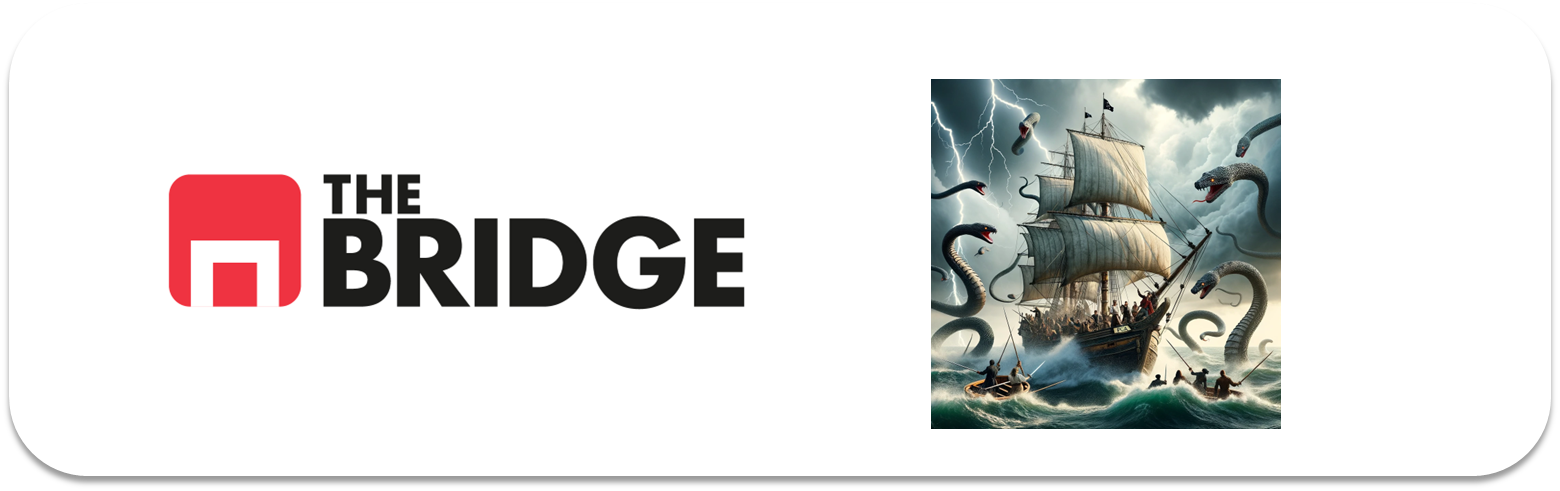

## PCA (III): Otras aplicaciones

### PARTE I: Visualización de relaciones: clustering y predicción

En esta primera parte vamos a ver muy brevemente y a título ilustrativo cómo usar la PCA para visualizar los datasets de una forma alternativa que puede servirnos para clusterizar o para comprobar la capacidad predictiva de las componentes en un dataset relativamente complejo.

Primero un poco de "teoría" que nos va a servir en ambos ejemplos:

Una imagen digital típica se compone apilando matrices de píxeles rojos, verdes y azules con intensidades que van de 0 a 255.

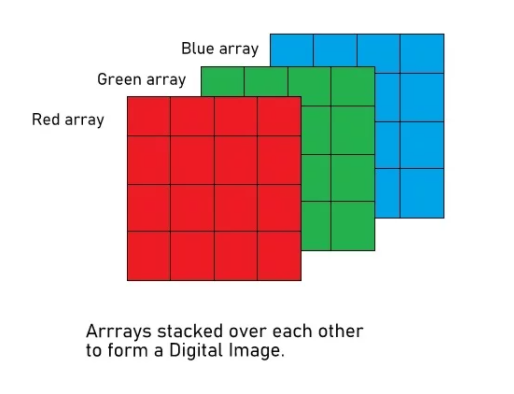

Una imagen en escala de grises no contiene color, sino solo tonos de gris. La intensidad del píxel en una imagen en escala de grises varía desde el negro (intensidad 0) hasta el blanco (intensidad completa 255) para hacer lo que normalmente llamamos una imagen en blanco y negro.

### Dataset

El conjunto de datos Digits es un conjunto de imágenes en escala de grises de dígitos escritos a mano que contiene 1797 imágenes de 8×8 y que vamos a emplear ahora:

In [1]:
# Cargamos el dataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
 
digits = load_digits()
data = digits.data
data.shape

(1797, 64)

La forma de los datos del `digits` dataset es (1797, 64). Es decir, 1797 instancias con 64 features (los 8×8 píxeles que se aplanan para crear un vector de longitud 64 para cada imagen). Ya es un número razonable para pensar en una posible PCA si las condiciones se dan (explicabilidad, reducción aceptable de precisión o de información, etc.).  

Podemos visualizar algunas instancias empleando `imshow` de pyplot con los datos debidamente "reshapeados" a 8x8:


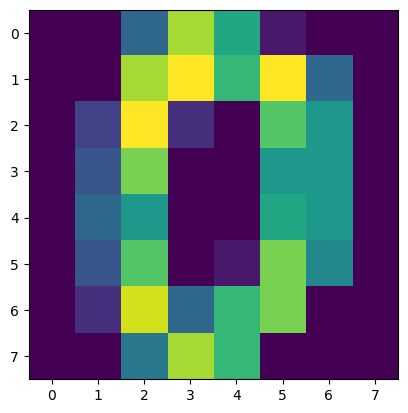

In [2]:
# Tomamos una imagen de ejemplo para visualizarla
# Recuerda que la imagen es un array de numpy
image_sample = data[0,:].reshape(8,8)
plt.imshow(image_sample);

Ahora, utilizando PCA, reduzcamos las dimensiones del dataset de 64 a solo 2 para que podamos visualizar el conjunto de datos usando un scatter plot y solo las dos primeras componentes. Fíjate en la forma de hacerlo: instanciamos la PCA con el número de componentes con el que queremos quedarnos; también podríamos haber puesto un valor entre 0 y 1 y se hubiera quedado con las componentes que aseguran un ratio acumulado de varianza igual o superior a ese valor entre 0 y 1:

In [3]:
# Importamos los módulos necesarios
from sklearn.decomposition import PCA
 
pca = PCA(2) # fíjate en la forma de instanciar la PCA
converted_data = pca.fit_transform(digits.data)
 
converted_data.shape

(1797, 2)

*Fíjate en que aquí no hemos escalado: todos los píxeles miden lo mismo (intensidad de 0 a 16), así que ya están en la misma escala. Estandarizar daría el mismo peso a los píxeles del borde, que casi nunca cambian, que a los del centro.*

Y ahora podemos visualizar el conjunto de datos haciendo un scatter de las dos componentes que mayor varianza conservan y colorearlo según el target (en este caso, el número que representa cada instancia de `digits`):

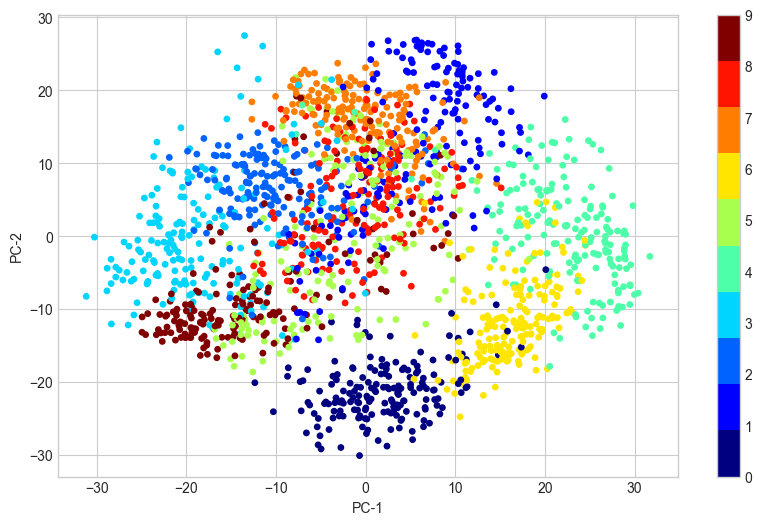

In [4]:
with plt.style.context('seaborn-v0_8-whitegrid'): # El estilo solo se aplica a este gráfico
    plt.figure(figsize = (10,6))
    c_map = plt.get_cmap('jet', 10)
    plt.scatter(converted_data[:, 0],
                converted_data[:, 1],
                s = 15,
                cmap = c_map ,
                c = digits.target)

    plt.colorbar()
    plt.xlabel('PC-1') , plt.ylabel('PC-2')
    plt.show()

En este caso lo que podemos ver es cómo las dos primeras componentes ya de por sí tienen bastante capacidad discriminativa para algunos de los dígitos (observa la separación del "0", o del "6", o el cluster de puntos del "1").

Esta misma aproximación nos puede servir para intentar visualizar datasets complejos de una forma reducida acudiendo a sus dos componentes principales o a una tercera que marque el color o una cuarta el tamaño de los puntos, etc., lo que además puede servirnos para detectar posibles agrupaciones o clusters. Es justo lo que haremos en la siguiente unidad, Clustering: buscaremos grupos en los datos y usaremos la PCA para visualizarlos en 2D.  



***

### Parte II: Compresión de imágenes

Otra aplicación interesante de PCA se encuentra en la compresión de imágenes. Echemos un vistazo a cómo podemos lograr esto con Python.

In [5]:
# Importamos las librerías necesarias
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

Vamos a cargar la imagen de un lindo "perrete" y la vamos a comprimir. Primero cargamos:

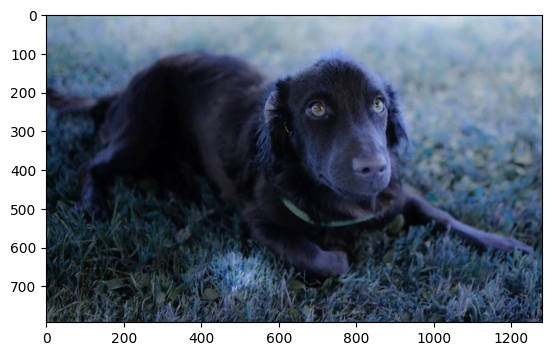

In [6]:
# Cargamos la imagen 
'''
OpenCV carga las imágenes en orden BGR, pero imshow de pyplot las interpreta como RGB, por lo que adquieren un tono azulado, como vas a comprobar
'''
img = cv2.imread('img/my_doggo_sample.jpeg') # Puedes usar la imagen que quieras
plt.imshow(img);

OpenCV carga los canales en orden BGR (azul, verde, rojo). Lo convertimos a RGB para que veas la imagen con sus colores originales:

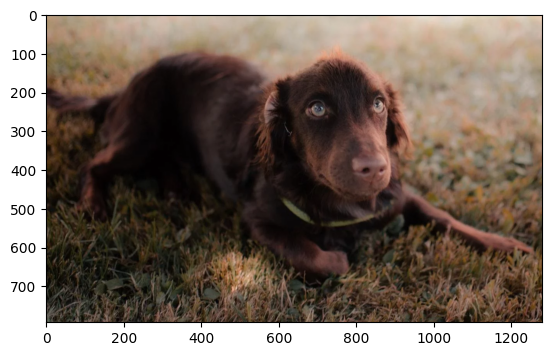

In [7]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

A partir de aquí trabajamos con la versión RGB, para que todas las imágenes que pintemos tengan sus colores reales:

In [8]:
# Separamos los canales en tres "datasets" ahora de un único valor: Rojo, Verde y Azul
red, green, blue = cv2.split(img_rgb)

In [9]:
print(blue.shape) # Se ha convertido en un array con la altura en píxeles, la anchura en píxeles y un único valor el del azul para cada uno de los píxeles de la imagen. 

(793, 1280)


Visto como un dataset, cada canal son 793 instancias con 1280 features.

Ojo con el orden de los canales: si hubiéramos separado directamente la imagen que carga OpenCV (BGR) el orden sería azul, verde y rojo. Como separamos `img_rgb`, el orden es rojo, verde y azul, y en ese mismo orden tendremos que volver a juntarlos.

Vamos a aplicar la PCA para quedarnos con las 20 componentes principales de esas 1280 features. Es decir, vamos a reducir, línea a línea de la imagen, los 1280 píxeles a 20 (x3 canales). Claro, esto no se podrá ver tal cual, luego tendremos que descomprimir y ver el resultado.

Hagamos la PCA de cada canal y luego usemos inverse_transform para obtener cada canal descomprimido:

In [10]:
# Inicializamos la PCA con las 20 primeras componentes principales
pca = PCA(20, random_state = 42) # Con tantas features sklearn usa un método aleatorizado: fijamos la semilla
 
# Aplicamos la PCA al canal rojo y después inverse_transform para descomprimirlo
red_transformed = pca.fit_transform(red)
print('red_transformed.shape:', red_transformed.shape)
red_inverted = pca.inverse_transform(red_transformed)
print('red_inverted.shape:', red_inverted.shape)
 
# Aplicamos la PCA al canal verde y después inverse_transform para descomprimirlo
green_transformed = pca.fit_transform(green)
print('green_transformed.shape:', green_transformed.shape)
green_inverted = pca.inverse_transform(green_transformed)
print('green_inverted.shape:', green_inverted.shape)
 
# Aplicamos la PCA al canal azul y después inverse_transform para descomprimirlo
blue_transformed = pca.fit_transform(blue)
print('blue_transformed.shape:', blue_transformed.shape)
blue_inverted = pca.inverse_transform(blue_transformed)
print('blue_inverted.shape:', blue_inverted.shape)

red_transformed.shape: (793, 20)
red_inverted.shape: (793, 1280)
green_transformed.shape: (793, 20)
green_inverted.shape: (793, 1280)
blue_transformed.shape: (793, 20)
blue_inverted.shape: (793, 1280)


NOTA: Separamos por canal porque no podemos hacer la PCA de features que sean vectores, recuerda que una imagen la puedes ver como una matriz de 2 dimensiones con tantas filas como píxeles tenga de alto, tantas columnas como píxeles tenga de ancho y cada valor de la matriz un vector de 3 dimensiones (una por cada canal de color) o bien como una tabla de tantas filas como píxeles tenga de alto, tantas features como píxeles de ancho y que cada feature sea un vector. Esto último no lo admite la PCA; por eso la hacemos canal por canal y luego juntamos los canales.

Hemos pasado de tener $793*1280*3$ valores a guardar $3*793*20$ proyecciones. Pero ojo: para poder descomprimir necesitamos guardar también, para cada canal, las componentes (`components_`, de $20*1280$) y la media de cada feature (`mean_`, de $1280$). Sin ellas no podríamos aplicar `inverse_transform`:

In [11]:
tam_inicial = img.size
tam_inicial

3045120

In [12]:
tam_proyecciones = red_transformed.size + green_transformed.size + blue_transformed.size
tam_compressed = tam_proyecciones + 3 * (pca.components_.size + pca.mean_.size) # components_ y mean_ tienen el mismo tamaño en los 3 canales
tam_proyecciones, tam_compressed

(47580, 128220)

In [13]:
print(f"Factor de compresión contando solo las proyecciones: {(1 - tam_proyecciones/tam_inicial):.1%}")
print(f"Factor de compresión real (con components_ y mean_): {(1 - tam_compressed/tam_inicial):.1%}")

Factor de compresión contando solo las proyecciones: 98.4%
Factor de compresión real (con components_ y mean_): 95.8%


Impresionante, pero veamos si la calidad de la reconstrucción merece la pena.

Mezclamos o juntamos los canales para reconstruir las imágenes. Tiramos un poco de NumPy y de cuando veíamos concatenaciones, en este caso apilamos los arrays de cada canal usando la función `dstack`. Aquí es importante especificar el tipo de datos de nuestros arrays, ya que la mayoría de las imágenes son de 8 bits: cada píxel de cada canal está representado por un byte, un entero entre 0 y 255 (`np.uint8`):

In [14]:
# dstack: apila los arrays en profundidad (a lo largo del tercer eje)
img_not_compressed = (np.dstack((red, green, blue))).astype(np.uint8)

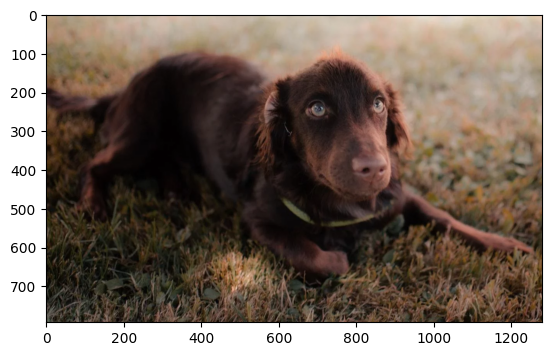

In [15]:
# Visualizamos la imagen sin comprimir
plt.imshow(img_not_compressed);

No te emociones, que esta es la imagen original (fíjate en que la hemos reconstruido a partir de los canales previamente separados). Veamos la comprimida, aplicando el mismo apilamiento o concatenación de arrays con `dstack`:

In [16]:
img_compressed_sin_clip = (np.dstack((red_inverted, green_inverted, blue_inverted))).astype(np.uint8)

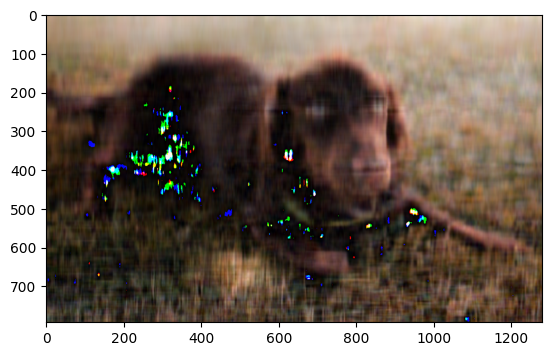

In [17]:
# Visualizamos la imagen comprimida
plt.imshow(img_compressed_sin_clip);

¿Y esos puntos de colores tan raros? No son culpa de la compresión, sino de la conversión a `uint8`. La reconstrucción de la PCA devuelve números reales que pueden salirse ligeramente del rango [0, 255]:

In [18]:
print("Mínimo reconstruido:", red_inverted.min().round(1), "- Máximo reconstruido:", red_inverted.max().round(1))
print("Ejemplo: -3 en uint8 es", np.array([-3]).astype(np.uint8)[0], "y 260 en uint8 es", np.array([260]).astype(np.uint8)[0])

Mínimo reconstruido: -10.9 - Máximo reconstruido: 246.3
Ejemplo: -3 en uint8 es 253 y 260 en uint8 es 4


Al convertir a `uint8` esos valores "dan la vuelta" (un píxel casi negro se vuelve casi blanco y viceversa). La solución es recortar los valores al rango válido con `np.clip` antes de convertir:

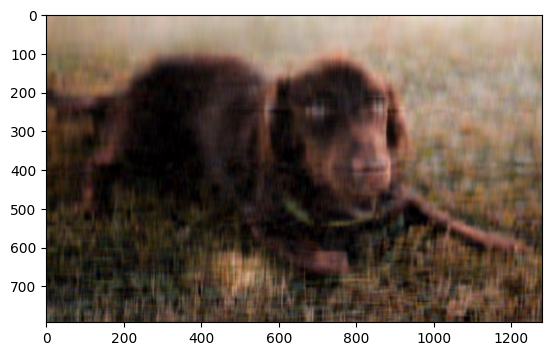

In [19]:
img_compressed = np.clip(np.dstack((red_inverted, green_inverted, blue_inverted)), 0, 255).astype(np.uint8)
plt.imshow(img_compressed);

El resultado anterior es lo que obtenemos al considerar solo 20 componentes principales: de lejos igual cuela, pero se ve borroso y el perrete se ha puesto triste. Podemos jugar a reducir el factor de compresión (quedándonos con más componentes) hasta llegar a un nivel aceptable:

Probemos con 60:

In [20]:
# Probamos con 60 PCs
pca = PCA(60, random_state = 42)

# Aplicamos la PCA al canal rojo y después inverse_transform para descomprimirlo
r_transformed = pca.fit_transform(red)
print('red_transformed.shape:', r_transformed.shape)
r_inverted = pca.inverse_transform(r_transformed)
print('red_inverted.shape:', r_inverted.shape)

# Aplicamos la PCA al canal verde y después inverse_transform para descomprimirlo
g_transformed = pca.fit_transform(green)
print('green_transformed.shape:', g_transformed.shape)
g_inverted = pca.inverse_transform(g_transformed)
print('green_inverted.shape:', g_inverted.shape)

# Aplicamos la PCA al canal azul y después inverse_transform para descomprimirlo
b_transformed = pca.fit_transform(blue)
print('blue_transformed.shape:', b_transformed.shape)
b_inverted = pca.inverse_transform(b_transformed)
print('blue_inverted.shape:', b_inverted.shape)

red_transformed.shape: (793, 60)
red_inverted.shape: (793, 1280)
green_transformed.shape: (793, 60)
green_inverted.shape: (793, 1280)
blue_transformed.shape: (793, 60)
blue_inverted.shape: (793, 1280)


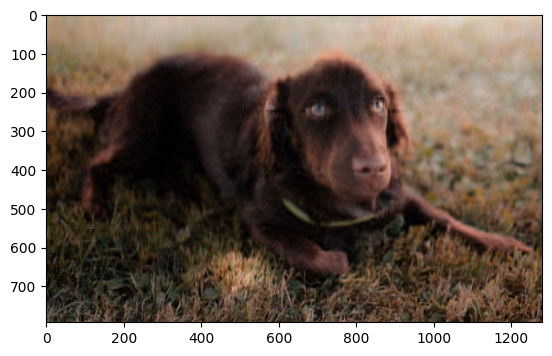

In [21]:
img_compressed_v2 = np.clip(np.dstack((r_inverted, g_inverted, b_inverted)), 0, 255).astype(np.uint8)
plt.imshow(img_compressed_v2);

Algo mejor el perro. ¿Y el factor de compresión? Si contamos solo las proyecciones parece muy alto, pero no olvides que hay que guardar también `components_` y `mean_`:

In [22]:
tam_60 = 3 * (r_transformed.size + pca.components_.size + pca.mean_.size)
print(f"Factor de compresión contando solo las proyecciones: {1 - 60/1280:.1%}")
print(f"Factor de compresión real: {1 - tam_60/img.size:.1%}")

Factor de compresión contando solo las proyecciones: 95.3%
Factor de compresión real: 87.6%


Del 95% "aparente" bajamos a un 88% real.

Podemos darle la vuelta: quedémonos con el 20% de las componentes, es decir 256 de las 1280 features (píxeles) por canal:

In [23]:
# Probamos con el 20% de las componentes (256 PCs)
pca = PCA(int(1280*0.2), random_state = 42)

# Aplicamos la PCA al canal rojo y después inverse_transform para descomprimirlo
r_transformed = pca.fit_transform(red)
print('red_transformed.shape:', r_transformed.shape)
r_inverted = pca.inverse_transform(r_transformed)
print('red_inverted.shape:', r_inverted.shape)

# Aplicamos la PCA al canal verde y después inverse_transform para descomprimirlo
g_transformed = pca.fit_transform(green)
print('green_transformed.shape:', g_transformed.shape)
g_inverted = pca.inverse_transform(g_transformed)
print('green_inverted.shape:', g_inverted.shape)

# Aplicamos la PCA al canal azul y después inverse_transform para descomprimirlo
b_transformed = pca.fit_transform(blue)
print('blue_transformed.shape:', b_transformed.shape)
b_inverted = pca.inverse_transform(b_transformed)
print('blue_inverted.shape:', b_inverted.shape)

red_transformed.shape: (793, 256)
red_inverted.shape: (793, 1280)


green_transformed.shape:

 (793, 256)
green_inverted.shape: (793, 1280)


blue_transformed.shape: (793, 256)
blue_inverted.shape: (793, 1280)


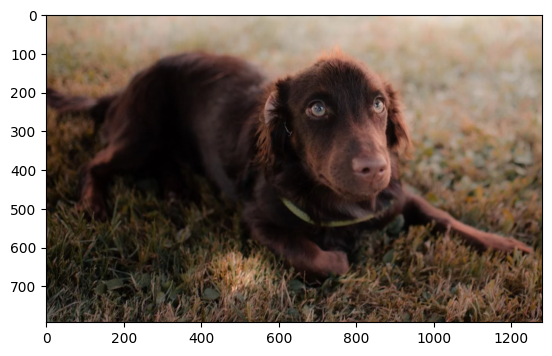

In [24]:
img_compressed_v2 = np.clip(np.dstack((r_inverted, g_inverted, b_inverted)), 0, 255).astype(np.uint8)
plt.imshow(img_compressed_v2);

Hmmm, no está nada mal. Pero veamos cuánto hemos comprimido de verdad:

In [25]:
tam_256 = 3 * (r_transformed.size + pca.components_.size + pca.mean_.size)
print(f"Factor de compresión real: {1 - tam_256/img.size:.1%}")

Factor de compresión real: 47.6%


*Quedarnos con el 20% de las componentes no significa guardar el 20% de los datos: `components_` (256 x 1280 por canal) ocupa casi tanto como las propias proyecciones, y la compresión real se queda por debajo del 50%.*

*Moraleja: para comprimir **una sola imagen** la PCA tiene sus límites (por algo existe JPEG 😉). Donde sí brilla es cuando comprimimos **muchas imágenes parecidas con la misma PCA**: `components_` y `mean_` se guardan una única vez y sirven para todas, así que el coste de cada imagen es solo el de sus proyecciones. Es justo el escenario que podéis probar en la práctica de la unidad.*